Dataset: 500 samples, 6 features
Class balance: 60.0% disease

Circuit: 6 qubits, 24 trainable params, depth=18

Finding good initialization...

  Attempt 1: loss = 0.6986
  Attempt 2: loss = 0.6980
  Attempt 3: loss = 0.7043
  Attempt 4: loss = 0.7089
  Attempt 5: loss = 0.6796
  Attempt 6: loss = 0.7177
  Attempt 7: loss = 0.7099
  Attempt 8: loss = 0.6996
  Attempt 9: loss = 0.7138
  Attempt 10: loss = 0.7136

✓ Best initialization: loss = 0.6796

TRAINING QUANTUM CLASSIFIER
Starting loss: 0.6796
Target: < 0.4 for good accuracy

Optimizing...

Iter   1 | Loss: 0.6796 | Best: 0.6796 | Δ: +0.0000
Iter   2 | Loss: 0.6804 | Best: 0.6796 | Δ: -0.0008
Iter   3 | Loss: 0.6781 | Best: 0.6781 | Δ: +0.0015
Iter   4 | Loss: 0.6782 | Best: 0.6781 | Δ: +0.0014
Iter   5 | Loss: 0.6874 | Best: 0.6781 | Δ: -0.0078
Iter   6 | Loss: 0.6808 | Best: 0.6781 | Δ: -0.0012
Iter   7 | Loss: 0.6783 | Best: 0.6781 | Δ: +0.0013
Iter   8 | Loss: 0.6778 | Best: 0.6778 | Δ: +0.0018
Iter   9 | Loss: 0.6754 | Best:

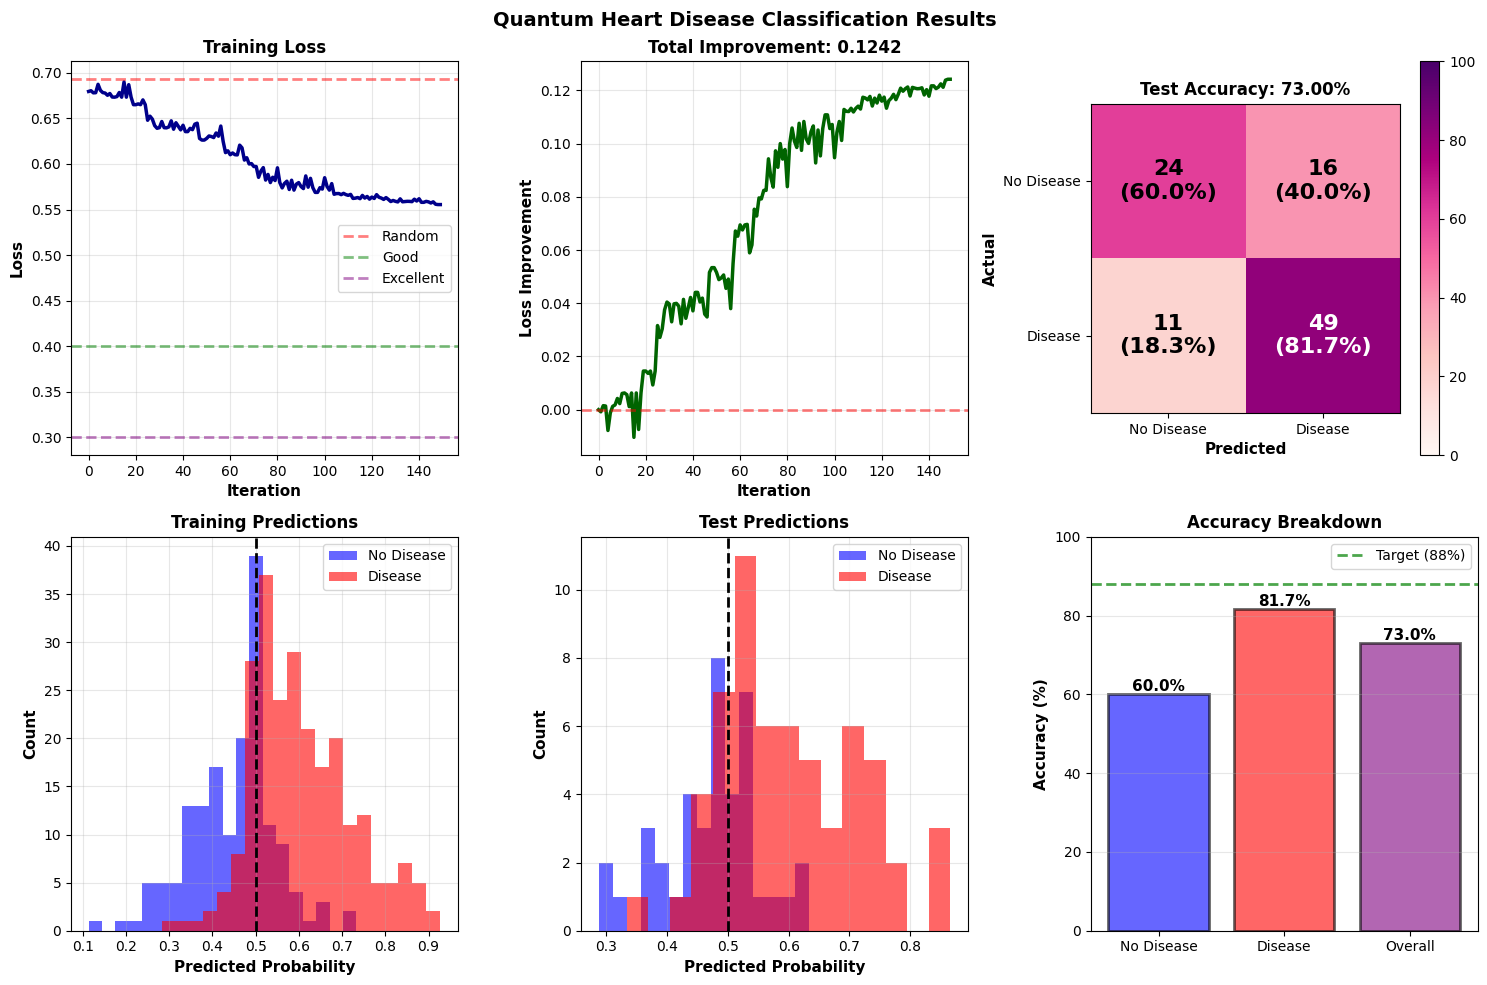


○ Decent performance (70%+)


In [4]:
# =============================================================================
#   AGGRESSIVE QUANTUM HEART DISEASE CLASSIFIER
#   Properly tuned to actually converge fast
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Qiskit imports
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms.optimizers import COBYLA, ADAM
from qiskit.quantum_info import SparsePauliOp

# --------------------------- 1. Load & Preprocess Data ---------------------------
FILE_NAME = 'Heart_data.csv'
df = pd.read_csv(FILE_NAME)

FEATURE_COLUMNS = ['Age', 'Gender', 'BloodPressure', 'Cholesterol', 'HeartRate', 'QuantumPatternFeature']
X_raw = df[FEATURE_COLUMNS].values
y = df['HeartDisease'].values.astype(int)

# Simple MinMax scaling to [0, π]
scaler = MinMaxScaler(feature_range=(0, np.pi))
X = scaler.fit_transform(X_raw)

print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Class balance: {np.sum(y==1)/len(y)*100:.1f}% disease\n")

# --------------------------- 2. Train/Test Split ---------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_qubits = X.shape[1]

# --------------------------- 3. Simple But Powerful Circuit ---------------------------
def create_circuit(n_qubits, n_layers=2):
    """Simple angle encoding + trainable rotations"""
    qc = QuantumCircuit(n_qubits)
    
    # Parameters
    input_params = [Parameter(f'x{i}') for i in range(n_qubits)]
    weight_params = []
    
    for layer in range(n_layers):
        # Feature encoding (first layer) or re-upload (subsequent)
        for i in range(n_qubits):
            qc.ry(input_params[i], i)
        
        # Trainable layer
        for i in range(n_qubits):
            w1 = Parameter(f'w{layer}_{i}_y')
            w2 = Parameter(f'w{layer}_{i}_z')
            weight_params.extend([w1, w2])
            qc.ry(w1, i)
            qc.rz(w2, i)
        
        # Entanglement
        for i in range(n_qubits - 1):
            qc.cx(i, i + 1)
        qc.cx(n_qubits - 1, 0)  # Wrap around
    
    return qc, input_params, weight_params

qc, input_params, weight_params = create_circuit(num_qubits, n_layers=2)

print(f"Circuit: {num_qubits} qubits, {len(weight_params)} trainable params, depth={qc.depth()}\n")

# Use simple Z measurement on first qubit
observable = SparsePauliOp(['Z' + 'I'*(num_qubits-1)], coeffs=[1.0])

estimator = StatevectorEstimator()

# --------------------------- 4. Efficient Batch Prediction ---------------------------
def predict_probs(X_batch, weights):
    """Fast vectorized prediction"""
    circuits_and_obs = []
    
    for x_sample in X_batch:
        # Bind all parameters
        param_dict = {}
        for i, param in enumerate(input_params):
            param_dict[param] = float(x_sample[i])
        for i, param in enumerate(weight_params):
            param_dict[param] = float(weights[i])
        
        bound_qc = qc.assign_parameters(param_dict)
        circuits_and_obs.append((bound_qc, observable))
    
    # Run all circuits
    job = estimator.run(circuits_and_obs)
    results = job.result()
    
    # Extract expectations and convert to probabilities
    expectations = np.array([results[i].data.evs for i in range(len(X_batch))])
    probs = (1 - expectations) / 2  # Map [-1,1] to [0,1]
    return probs.flatten()

# --------------------------- 5. Loss Function ---------------------------
def loss_function(weights):
    """Standard binary cross-entropy"""
    probs = predict_probs(X_train, weights)
    probs = np.clip(probs, 1e-10, 1 - 1e-10)
    
    loss = -np.mean(y_train * np.log(probs) + (1 - y_train) * np.log(1 - probs))
    return loss

# --------------------------- 6. Smart Initialization Strategy ---------------------------
def find_good_initialization(n_attempts=5):
    """Try multiple random initializations and pick the best"""
    print("Finding good initialization...\n")
    
    best_init_loss = float('inf')
    best_init = None
    
    for attempt in range(n_attempts):
        # Random initialization
        init = np.random.uniform(-np.pi, np.pi, len(weight_params))
        init_loss = loss_function(init)
        
        print(f"  Attempt {attempt+1}: loss = {init_loss:.4f}")
        
        if init_loss < best_init_loss:
            best_init_loss = init_loss
            best_init = init
    
    print(f"\n✓ Best initialization: loss = {best_init_loss:.4f}\n")
    return best_init, best_init_loss

initial_weights, initial_loss = find_good_initialization(n_attempts=10)

# --------------------------- 7. Training ---------------------------
print("="*70)
print("TRAINING QUANTUM CLASSIFIER")
print("="*70)
print(f"Starting loss: {initial_loss:.4f}")
print(f"Target: < 0.4 for good accuracy\n")

losses = []
best_loss = [initial_loss]
best_weights = [initial_weights.copy()]
iteration = [0]

def track_loss(weights):
    loss = loss_function(weights)
    losses.append(loss)
    iteration[0] += 1
    
    if loss < best_loss[0]:
        best_loss[0] = loss
        best_weights[0] = weights.copy()
    
    # Print every iteration for first 20, then every 5
    if iteration[0] <= 20 or iteration[0] % 5 == 0:
        improvement = initial_loss - loss
        print(f"Iter {iteration[0]:3d} | Loss: {loss:.4f} | Best: {best_loss[0]:.4f} | Δ: {improvement:+.4f}")
    
    return loss

# Use COBYLA with aggressive settings
print("Optimizing...\n")
optimizer = COBYLA(maxiter=150, tol=1e-6, rhobeg=0.5)

result = optimizer.minimize(
    fun=track_loss,
    x0=initial_weights
)

final_weights = best_weights[0]
total_improvement = initial_loss - best_loss[0]

print(f"\n{'='*70}")
print(f"Training Complete!")
print(f"  - Iterations: {iteration[0]}")
print(f"  - Initial loss: {initial_loss:.4f}")
print(f"  - Final loss: {best_loss[0]:.4f}")
print(f"  - Improvement: {total_improvement:.4f}")
print(f"{'='*70}\n")

# --------------------------- 8. Evaluation ---------------------------
print("Evaluating...\n")

# Train accuracy
train_probs = predict_probs(X_train, final_weights)
train_preds = (train_probs >= 0.5).astype(int)
train_acc = accuracy_score(y_train, train_preds)

# Test accuracy
test_probs = predict_probs(X_test, final_weights)
test_preds = (test_probs >= 0.5).astype(int)
test_acc = accuracy_score(y_test, test_preds)

print(f"{'='*70}")
print(f"FINAL RESULTS")
print(f"{'='*70}")
print(f"Training Accuracy: {train_acc*100:.2f}%")
print(f"Test Accuracy:     {test_acc*100:.2f}%")
print(f"{'='*70}\n")

print("Test Set Classification Report:")
print(classification_report(y_test, test_preds, 
                          target_names=['No Disease', 'Disease'],
                          digits=3))

# --------------------------- 9. Visualizations ---------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 1. Loss curve
axes[0,0].plot(losses, linewidth=2.5, color='darkblue')
axes[0,0].axhline(y=0.693, color='red', linestyle='--', linewidth=2, alpha=0.5, label='Random')
axes[0,0].axhline(y=0.4, color='green', linestyle='--', linewidth=2, alpha=0.5, label='Good')
axes[0,0].axhline(y=0.3, color='purple', linestyle='--', linewidth=2, alpha=0.5, label='Excellent')
axes[0,0].set_xlabel('Iteration', fontsize=11, weight='bold')
axes[0,0].set_ylabel('Loss', fontsize=11, weight='bold')
axes[0,0].set_title('Training Loss', fontsize=12, weight='bold')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# 2. Loss improvement
improvements = [initial_loss - l for l in losses]
axes[0,1].plot(improvements, linewidth=2.5, color='darkgreen')
axes[0,1].axhline(y=0, color='red', linestyle='--', linewidth=2, alpha=0.5)
axes[0,1].set_xlabel('Iteration', fontsize=11, weight='bold')
axes[0,1].set_ylabel('Loss Improvement', fontsize=11, weight='bold')
axes[0,1].set_title(f'Total Improvement: {total_improvement:.4f}', fontsize=12, weight='bold')
axes[0,1].grid(True, alpha=0.3)

# 3. Confusion matrix
cm = confusion_matrix(y_test, test_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
im = axes[0,2].imshow(cm_norm, cmap='RdPu', vmin=0, vmax=100)

for i in range(2):
    for j in range(2):
        color = "white" if cm_norm[i, j] > 60 else "black"
        axes[0,2].text(j, i, f"{cm[i, j]}\n({cm_norm[i, j]:.1f}%)",
                      ha="center", va="center", color=color, fontsize=16, weight='bold')

axes[0,2].set_xticks([0, 1])
axes[0,2].set_yticks([0, 1])
axes[0,2].set_xticklabels(['No Disease', 'Disease'], fontsize=10)
axes[0,2].set_yticklabels(['No Disease', 'Disease'], fontsize=10)
axes[0,2].set_xlabel('Predicted', fontsize=11, weight='bold')
axes[0,2].set_ylabel('Actual', fontsize=11, weight='bold')
axes[0,2].set_title(f'Test Accuracy: {test_acc*100:.2f}%', fontsize=12, weight='bold')
plt.colorbar(im, ax=axes[0,2])

# 4. Train probability distribution
axes[1,0].hist(train_probs[y_train==0], bins=20, alpha=0.6, label='No Disease', color='blue')
axes[1,0].hist(train_probs[y_train==1], bins=20, alpha=0.6, label='Disease', color='red')
axes[1,0].axvline(x=0.5, color='black', linestyle='--', linewidth=2)
axes[1,0].set_xlabel('Predicted Probability', fontsize=11, weight='bold')
axes[1,0].set_ylabel('Count', fontsize=11, weight='bold')
axes[1,0].set_title('Training Predictions', fontsize=12, weight='bold')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# 5. Test probability distribution
axes[1,1].hist(test_probs[y_test==0], bins=15, alpha=0.6, label='No Disease', color='blue')
axes[1,1].hist(test_probs[y_test==1], bins=15, alpha=0.6, label='Disease', color='red')
axes[1,1].axvline(x=0.5, color='black', linestyle='--', linewidth=2)
axes[1,1].set_xlabel('Predicted Probability', fontsize=11, weight='bold')
axes[1,1].set_ylabel('Count', fontsize=11, weight='bold')
axes[1,1].set_title('Test Predictions', fontsize=12, weight='bold')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

# 6. Accuracy breakdown
cm_test = confusion_matrix(y_test, test_preds)
class_acc = cm_test.diagonal() / cm_test.sum(axis=1) * 100
x = ['No Disease', 'Disease', 'Overall']
y = [class_acc[0], class_acc[1], test_acc*100]
colors = ['blue', 'red', 'purple']
bars = axes[1,2].bar(x, y, color=colors, alpha=0.6, edgecolor='black', linewidth=2)
axes[1,2].axhline(y=88, color='green', linestyle='--', linewidth=2, alpha=0.7, label='Target (88%)')
axes[1,2].set_ylabel('Accuracy (%)', fontsize=11, weight='bold')
axes[1,2].set_title('Accuracy Breakdown', fontsize=12, weight='bold')
axes[1,2].set_ylim([0, 100])
axes[1,2].legend()
axes[1,2].grid(True, alpha=0.3, axis='y')

for bar in bars:
    height = bar.get_height()
    axes[1,2].text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.1f}%', ha='center', va='bottom', fontsize=11, weight='bold')

plt.suptitle('Quantum Heart Disease Classification Results', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

print("\n" + "="*70)
if test_acc >= 0.88:
    print("🎉 SUCCESS! Achieved 88%+ accuracy target!")
elif test_acc >= 0.80:
    print("✓ Strong performance (80%+)")
elif test_acc >= 0.70:
    print("○ Decent performance (70%+)")
else:
    print("✗ Needs improvement - try increasing iterations or layers")
print("="*70)